In [ ]:
# Importação das bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt   

# Definição do caminho dos dados
caminho_dados = "BaseVarejoDadosBrutos.csv"

In [ ]:
# Leitura dos dados com a utilização dos parâmetros abaixo:
# dtype - para que as colunas que devem ser do tipo string, não sejam lidas como do tipo inteiro
# parse_dates - para instruir o pandas a interpretar a coluna DATA como data/datetime
# na_values - para definir que o valor "#N/D" seja tratado como valor ausente (NaN).
# keep_default_na=True - para que além de "#N/D", outros valores padrão, reconhecidos como ausentes, também sejam convertidos para NaN
df = pd.read_csv(caminho_dados, sep= ";", dtype= {"CO_ID": "string", 
                                                  "CL_ID": "string", 
                                                  "PR_ID": "string"},
                                                  parse_dates=["DATA"],na_values=["#N/D"], keep_default_na=True)

In [ ]:
# Exibição da lista com os nomes de todas as colunas, para analisar os nomes e possíveis inconsistências
print("Nome das colunas:" , df.columns.tolist())

Nome das colunas: ['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13']


In [4]:
# Exibição das 3 primeiras linhas do dataframe
df.head(3)

,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,01/02/2019,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA,NaN,NaN,NaN,NaN
1,01/02/2019,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS,NaN,NaN,NaN,NaN
2,01/02/2019,1000,534,M,4,1,C,178,HIGIENE,LENCO UMEDECIDO,NaN,NaN,NaN,NaN


In [5]:
# Verificação do tamanho do conjunto de dados
print("Total de linhas:", df.shape[0])
print("Total de colunas:", df.shape[1])

Total de linhas: 830000
Total de colunas: 14


In [6]:
# Inspeção dos tipos dos dados de cada coluna e nulos presentes em cada uma delas
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 830000 entries, 0 to 829999
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   DATA         830000 non-null  object 
 1   CO_ID        830000 non-null  string 
 2   CL_ID        830000 non-null  string 
 3   CL_GENERO    830000 non-null  object 
 4   CL_EC        830000 non-null  int64  
 5   CL_FHL       830000 non-null  int64  
 6   CL_SEG       830000 non-null  object 
 7   PR_ID        830000 non-null  string 
 8   PR_CAT       826350 non-null  object 
 9   PR_NOME      826350 non-null  object 
 10  Unnamed: 10  0 non-null       float64
 11  Unnamed: 11  0 non-null       float64
 12  Unnamed: 12  0 non-null       float64
 13  Unnamed: 13  0 non-null       float64
dtypes: float64(4), int64(2), object(5), string(3)
memory usage: 88.7+ MB


### Dicionário de dados

1. DATA: Data da compra;  
2. CO_ID: Identificação do número de compra (número da nota fiscal);  
3. CL_ID: Identificação do cliente (número do cliente);  
4. CL_GENERO: Sexo biológico informado pelo cliente;  
5. CL_EC: Estado civil do cliente:  1: Casado ou união estával; 2: Divorciado; 3: Separado;  4: Solteiro;  5: Viúvo.  
6. CL_FHL: Número de filhos do cliente;  
7. CL_SEG: Segmentação econômica do cliente (classe A, B ou C);  
8. PR_ID: Código do produto (SKU) adquirido;  
9. PR_CAT: Categoria do produto adquirido;  
10. PR_NOME: Nome do produto adquirido. 

In [7]:
# Conversão do tipo da coluna DATA de string para datetime
print("Tipo da coluna DATA antes da transformação:" , df["DATA"].dtype)
df["DATA"] = pd.to_datetime(df["DATA"], format = "%d/%m/%Y")
print("Tipo da coluna DATA após a transformação:" , df["DATA"].dtype)


Tipo da coluna DATA antes da transformação: object
Tipo da coluna DATA após a transformação: datetime64[ns]


In [8]:
# Identificação da data inicial e final do registro dos dados
print("Período compreendido entre:")
print(df["DATA"].min().strftime("%d/%m/%Y"), "e", df["DATA"].max().strftime("%d/%m/%Y"))

Período compreendido entre:
04/01/2019 e 08/12/2022


In [9]:
# Filtro de período, com o intuito de considerar somente os meses completos
# Janeiro/2019 e dezembro/2022 estão incompletos: a base começa no dia 4 e termina no dia 8, por isso esses dois meses foram deixados de fora.
df = df[(df["DATA"] >= "2019-02-01") & (df["DATA"] < "2022-12-01")]

In [10]:
# Verificação de presença de nulos e respectiva contagem 
print("Total de nulos por coluna:")
print(df.isnull().sum())

Total de nulos por coluna:
DATA                0
CO_ID               0
CL_ID               0
CL_GENERO           0
CL_EC               0
CL_FHL              0
CL_SEG              0
PR_ID               0
PR_CAT           3557
PR_NOME          3557
Unnamed: 10    807625
Unnamed: 11    807625
Unnamed: 12    807625
Unnamed: 13    807625
dtype: int64


In [11]:
# Percentual de nulos em cada coluna - o quanto representam em relação ao todo
print(df.isnull().mean()*100)

DATA             0.000000
CO_ID            0.000000
CL_ID            0.000000
CL_GENERO        0.000000
CL_EC            0.000000
CL_FHL           0.000000
CL_SEG           0.000000
PR_ID            0.000000
PR_CAT           0.440427
PR_NOME          0.440427
Unnamed: 10    100.000000
Unnamed: 11    100.000000
Unnamed: 12    100.000000
Unnamed: 13    100.000000
dtype: float64


In [12]:
# Seleção das colunas válidas: selecionadas somentes as colunas contendo dados válidos
df = df[['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME']]

In [13]:
# Tratamento dos dados nulos

# Foram identificados dados nulos em PR_CAT (Categoria do produto) e PR_NOME(Nome do produto)

# Antes do tratamento dos dados nulos, buscou-se analisar a consistência dos dados, verificando se um 
# PR_ID (identificador do produtp) não está associado a mais de um valor diferente de PR_CAT ou de PR_NOME.

# Deste modo, foram seguidos os seguintes passos:
# 1 - Levantamento de somente valores válidos através da exclusão dos
#  valores que eventualmente estejam simultaneamente nulos em PR_CAT e PR_NOME
validos = df.dropna(subset=["PR_CAT", "PR_NOME"])


# 2 Verificar se um mesmo PR_ID não está associado a mais de um valor diferente de PR_CAT ou de PR_NOME 
#Para cada PR_ID, contamos quantos valores distintos existem em PR_CAT e em PR_NOME. Se um ID tem sempre 
#a mesma categoria e o mesmo nome, o resultado será 1 em ambas as colunas — o esperado.
conflitos = (validos.groupby("PR_ID")[["PR_CAT", "PR_NOME"]].nunique().query("PR_CAT >1 or PR_NOME > 1"))
print(f"IDs com conflito: {len(conflitos)}")
conflitos.head()

# 3. Construção da tabela de referência dos produtos
# Após a verificação da consistência, foi construída uma tabela de referência
# contendo o identificador, a categoria e o nome de cada produto.
# A tabela utiliza PR_ID como índice, facilitando a consulta das informações
# válidas para posterior preenchimento dos valores nulos.
tabela_ref_produtos = (validos
               .drop_duplicates("PR_ID")[["PR_ID", "PR_CAT", "PR_NOME"]]
               .set_index("PR_ID"))

print("Tabela contendo os ids de todos os produtos vendidos pela empresa")
print(tabela_ref_produtos.head())

IDs com conflito: 0
Tabela contendo os ids de todos os produtos vendidos pela empresa
          PR_CAT               PR_NOME
PR_ID                                 
67       BEBIDAS  REFRIGERANTE GUARANA
70       BEBIDAS   REFRIGERANTE OUTROS
178      HIGIENE       LENCO UMEDECIDO
4      ALIMENTOS               ABACAXI
175      LIMPEZA     LIMPADOR MULTIUSO


In [14]:
# Contabilização dos ids únicos de produtos do df principal (vendas)
# Observação: O set() transforma uma coleção de valores em um conjunto de elementos únicos
ids_vendas = set(df["PR_ID"].dropna().unique()) 

# Contabilização dos ids únicos de produtos da tabela de referência criada
ids_referencia = set(tabela_ref_produtos.index)

# Número total de ids de produtos regitrados na tabela de vendas, mas não presente na tabela de referência
ids_nao_encontrados = ids_vendas - ids_referencia

print(
    f"Total de IDs de produtos não encontrados "
    f"na tabela de referência: {len(ids_nao_encontrados)}"
)

Total de IDs de produtos não encontrados na tabela de referência: 1


In [15]:
# Contagem dos nulos antes do preenchimento
nulos_antes = df[["PR_CAT", "PR_NOME"]].isnull().sum()
print("Total de nulos antes do preenchimento:")
print(nulos_antes)

Total de nulos antes do preenchimento:
PR_CAT     3557
PR_NOME    3557
dtype: int64


In [16]:
# Preenchimento dos nulos como "NAO INFORMADO" (Que, portanto, não existem na tabela de referência)
df["PR_CAT"]  = (df["PR_CAT"]
                 .fillna(df["PR_ID"].map(tabela_ref_produtos["PR_CAT"]))
                 .fillna("NAO INFORMADO"))

df["PR_NOME"] = (df["PR_NOME"]
                 .fillna(df["PR_ID"].map(tabela_ref_produtos["PR_NOME"]))
                 .fillna("NAO INFORMADO"))

In [17]:
# Contagem dos nulos após o preenchimento
nulos_apos = df[["PR_CAT", "PR_NOME"]].isnull().sum()
print("Total de nulos após o preenchimento:")
print(nulos_apos)



Total de nulos após o preenchimento:
PR_CAT     0
PR_NOME    0
dtype: int64


In [18]:
# Verificando inconsistências nos nomes de produtos e categorias
nomes_produtos = df["PR_NOME"].unique()
print(sorted(nomes_produtos, key=str.lower))

nomes_categorias = df["PR_CAT"].unique()
print(sorted(nomes_categorias, key=str.lower))


['ABACATE', 'ABACAXI', 'ABSORVENTE', 'ACHOCOLATADO', 'AGUA SANITARIA', 'ALCOOL', 'ALHO', 'ALIMENTO PARA PASSARO', 'ALMONDEGA', 'AMACIANTE', 'ARROZ', 'ARROZ INTEGRAL', 'ATUM', 'AZEITE', 'AZEITONA', 'BALDE', 'BANANA', 'BATATA', 'BATATA DOCE', 'BIFE DE COXAO MOLE', 'BISCOITO', 'BROCOLIS', 'CAFE', 'CEBOLA', 'CENOURA', 'CERA', 'CHA', 'CHUPETA', 'COGUMELOS', 'CONDICIONADOR', 'COPA SUINA', 'CORACAO DE FRANGO', 'COXA E SOBRECOXA DE FRANGO', 'CREME', 'DANETTE', 'DESENGORDURANTE', 'DESINFETANTE', 'DETERGENTE', 'DOCE', 'ENERGETICO', 'ENXAGUANTE BUCAL', 'ESCOVA DE DENTE', 'FEIJAO', 'FILE DE PEIXE', 'FIO DENTAL', 'FIXADOR', 'FRALDA', 'GEL', 'GRANOLA', 'HAMBUGUER', 'HASTES FLEXIVEIS', 'HIDRATANTE', 'INSETICIDA', 'IOGURTE', 'KETCHUP', 'LATA DE ERVILHA', 'LATA DE MILHO', 'LEITE', 'LEITE CONDENSADO', 'LENCO UMEDECIDO', 'LIMAO', 'LIMPA VIDROS', 'LIMPADOR MULTIUSO', 'LIMPADOR PERFUMADO', 'LINGUICA', 'LUSTRA MOVEIS', 'MACARRAO', 'MACARRAO INSTANTANEO', 'MAMAO', 'MAMAO PAPAYA', 'MANGA', 'MODELADOR', 'MOLHO

In [19]:
# Tratamento dos nomes dos produtos - padronização para CAIXA ALTA
df['PR_NOME'] = df['PR_NOME'].str.upper()

In [20]:
# Identificação de duplicados
print("Total de duplicados exatos encontrados:", df.duplicated().sum())
percentual_duplicados = (df.duplicated().sum()) / (len(df))
print(f"Percentual de duplicados: {percentual_duplicados:.2f}%")

# Visualizar os duplicados
duplicados = df[df.duplicated()]


Total de duplicados exatos encontrados: 93874
Percentual de duplicados: 0.12%


In [21]:
# Visualizar todos os duplicados
df_duplic = df[df.duplicated(keep=False)]
df_duplic.sort_values(by=["CL_ID","PR_NOME"])

,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME
367037,2020-05-10,404190,1,M,1,0,C,71,HIGIENE,ABSORVENTE
367039,2020-05-10,404190,1,M,1,0,C,71,HIGIENE,ABSORVENTE
532764,2021-06-06,586940,1,M,1,0,C,5,ALIMENTOS,ACHOCOLATADO
532767,2021-06-06,586940,1,M,1,0,C,5,ALIMENTOS,ACHOCOLATADO
260369,2020-03-04,289039,1,M,1,0,C,115,PET,ALIMENTO PARA PASSARO
...,...,...,...,...,...,...,...,...,...,...
222463,2020-10-02,247893,999,M,2,2,C,63,ALIMENTOS,TOMATE
320074,2020-07-17,355535,999,M,2,2,C,114,LIMPEZA,VASSOURA
320159,2020-07-17,355535,999,M,2,2,C,114,LIMPEZA,VASSOURA
452280,2021-02-14,497738,999,M,2,2,C,120,LIMPEZA,VASSOURA


In [22]:
# Criação coluna CL_EC_EXTENSO

estado_civil_clientes = {
    1: "CASADO OU UNIAO ESTAVEL",
    2: "DIVORCIADO",
    3: "SEPARADO",
    4: "SOLTEIRO",
    5: "VIUVO"
}

df["CL_EC_DESC"] = df["CL_EC"].map(estado_civil_clientes)
df.head()


,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,CL_EC_DESC
0,2019-02-01,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA,SOLTEIRO
1,2019-02-01,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS,SOLTEIRO
2,2019-02-01,1000,534,M,4,1,C,178,HIGIENE,LENCO UMEDECIDO,SOLTEIRO
3,2019-02-01,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI,SOLTEIRO
4,2019-02-01,1000,534,M,4,1,C,175,LIMPEZA,LIMPADOR MULTIUSO,SOLTEIRO


In [23]:
# Colunas DIA, MES E ANO
df["DIA"] = df.DATA.dt.day
df["MES"] = df.DATA.dt.month
df["ANO"] = df.DATA.dt.year

In [24]:
# Contagem de valores das colunas criadas e possíveis nulos 

# Coluna CL_EC_DESC
df["CL_EC_DESC"].value_counts(dropna=False)

# Coluna ANO
df["ANO"].value_counts(dropna=False)

# Coluna MES
df["MES"].value_counts(dropna=False)

MES
5     82275
1     76595
2     76201
10    73900
7     68983
9     68594
6     67808
4     66935
8     65609
3     64371
12    55442
11    40912
Name: count, dtype: int64

In [25]:
# Primeiras 2 linhas do df com as novas colunas 
df.head(2)

,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,CL_EC_DESC,DIA,MES,ANO
0,2019-02-01,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA,SOLTEIRO,1,2,2019
1,2019-02-01,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS,SOLTEIRO,1,2,2019


In [26]:
# Tabela de clientes com dados referentes a gênero, estado civil, nº de filhos, segmento social e total de compras
clientes = df.groupby(["CL_ID","CL_GENERO", "CL_EC_DESC", "CL_FHL","CL_SEG"])["CO_ID"].nunique().reset_index()
clientes.head()

,CL_ID,CL_GENERO,CL_EC_DESC,CL_FHL,CL_SEG,CO_ID
0,1,M,CASADO OU UNIAO ESTAVEL,0,C,14
1,10,M,CASADO OU UNIAO ESTAVEL,0,B,19
2,100,F,DIVORCIADO,3,C,15
3,1000,F,SOLTEIRO,1,B,16
4,101,F,CASADO OU UNIAO ESTAVEL,0,C,22


---------- PERFIL DOS CLIENTES ----------
Total de clientes: 1000

Clientes por gênero:
CL_GENERO
F    519
M    481
Name: count, dtype: int64

Clientes por estado civil:
CL_EC_DESC
SOLTEIRO                   251
SEPARADO                   250
DIVORCIADO                 238
CASADO OU UNIAO ESTAVEL    233
VIUVO                       28
Name: count, dtype: int64

Número de filhos:
count    1000.00000
mean        1.13600
std         1.41333
min         0.00000
25%         0.00000
50%         0.00000
75%         2.00000
max         4.00000
Name: CL_FHL, dtype: float64
Clientes com filhos: 473
Clientes sem filhos: 527

Clientes por segmento econômico:
CL_SEG
B    645
C    271
A     84
Name: count, dtype: int64

 ---------- PEDIDOS E ITENS ----------

Total de pedidos: 17987
Total de itens vendidos: 807625

---------- PEDIDOS POR CLIENTE E OUTLIERS ----------

Média de pedidos por cliente: 17.99
count    1000.00000
mean       17.98700
std         4.26955
min         6.00000
25%        15.0000

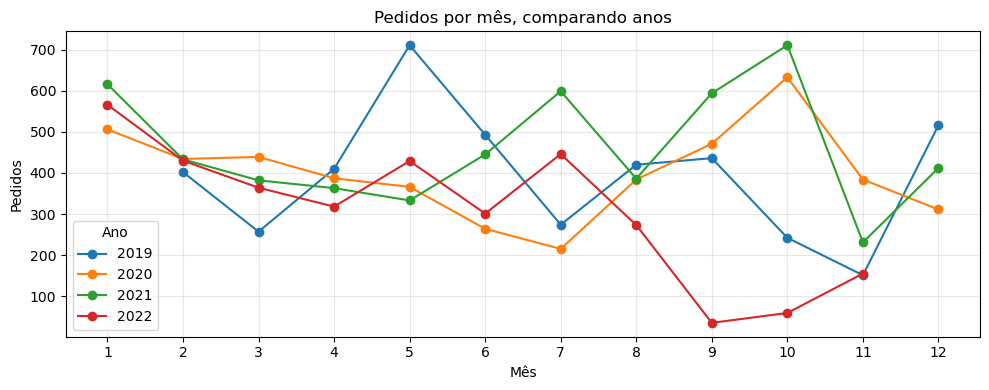

In [27]:
print( "---------- PERFIL DOS CLIENTES ----------")
print("Total de clientes:", df["CL_ID"].nunique())

print("\nClientes por gênero:")
print(clientes["CL_GENERO"].value_counts())

print("\nClientes por estado civil:")
print(clientes["CL_EC_DESC"].value_counts())

print("\nNúmero de filhos:")
print(clientes["CL_FHL"].describe())
print("Clientes com filhos:", (clientes["CL_FHL"] > 0).sum())
print("Clientes sem filhos:", (clientes["CL_FHL"] == 0).sum())

print("\nClientes por segmento econômico:")
print(clientes["CL_SEG"].value_counts())

print("\n ---------- PEDIDOS E ITENS ----------")
total_pedidos = df["CO_ID"].nunique()
total_itens = len(df)  
print("\nTotal de pedidos:", total_pedidos)
print("Total de itens vendidos:", total_itens)

print("\n---------- PEDIDOS POR CLIENTE E OUTLIERS ----------")
pedidos_cliente = df.groupby("CL_ID")["CO_ID"].nunique()

print("\nMédia de pedidos por cliente:", round(pedidos_cliente.mean(), 2))
print(pedidos_cliente.describe())

# Outliers pelo método IQR
q1, q3 = pedidos_cliente.quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
outliers = pedidos_cliente[pedidos_cliente > limite].sort_values(ascending=False)

print(f"\nLimite superior (IQR): {limite:.1f} pedidos")
print("Clientes outliers:", len(outliers))
print(outliers.head(10))

# Peso dos outliers no total de pedidos
print(f"Outliers concentram {outliers.sum() / total_pedidos:.1%} dos pedidos")

print("\n---------- CATEGORIAS E PRODUTOS ----------")
print("\nCategorias mais vendidas (quantidade de itens):")
print(df["PR_CAT"].value_counts())

print("\nTop 10 produtos (quantidade de itens):")
print(df["PR_NOME"].value_counts().head(10))

print("\n---------- QUEM COMPRA MAIS ----------")
compras_por_estado_civil = df.groupby("CL_EC_DESC")["CO_ID"].nunique().reset_index().sort_values(by="CO_ID", ascending=False)
print("\nTotal de pedidos por estado civil:") 
print(compras_por_estado_civil)

compras_por_genero = df.groupby("CL_GENERO")["CO_ID"].nunique().reset_index().sort_values(by="CO_ID", ascending=False)
print("\nTotal de pedidos por gênero:") 
print(compras_por_genero)

compras_por_compos_familiar = df.groupby("CL_FHL")["CO_ID"].nunique().reset_index().sort_values(by="CO_ID", ascending=False)
print("\nTotal de pedidos de acordo com o número de filhos:")
print(compras_por_compos_familiar)

compras_por_seg_economico = df.groupby("CL_SEG")["CO_ID"].nunique().reset_index().sort_values(by="CO_ID", ascending=False)
print("\nTotal de pedidos de acordo com o número de filhos:")
print(compras_por_seg_economico)

print("\n---------- COMO VARIAM AS VENDAS AO LONGO DO TEMPO ----------")

vendas_por_mes_e_ano = (
    df.groupby(["MES","ANO"])["CO_ID"]
           .nunique()
           .unstack()
)

fig, ax = plt.subplots(figsize=(10, 4))
vendas_por_mes_e_ano.plot(ax=ax, marker="o")
ax.set_title("Pedidos por mês, comparando anos")
ax.set_xlabel("Mês")
ax.set_ylabel("Pedidos")
ax.set_xticks(range(1, 13))
ax.legend(title="Ano")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
